In [2]:
import pandas as pd
import numpy as np

In [3]:
columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

df = pd.read_csv('/content/adult.data', names=columns, skipinitialspace=True)
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [5]:
# Barcha '?' belgilarini standart NaN ga o'tkazamiz
df.replace('?', np.nan, inplace=True)

# Qaysi ustunlarda qanchadan bo'sh qiymat borligini ko'ramiz
missing_counts = df.isnull().sum()
print("Bo'sh qiymatlar soni:")
print(missing_counts[missing_counts > 0])

Bo'sh qiymatlar soni:
workclass         1836
occupation        1843
native_country     583
dtype: int64


In [6]:
# Har uchala ustun bo'shliqlarini moda bilan to'ldiramiz
for col in ['workclass', 'occupation', 'native_country']:
    df[col].fillna(df[col].mode()[0], inplace=True)

# Bo'sh qiymatlar qolmaganini tekshiramiz
print("Tozalashdan keyin umumiy NaN soni:", df.isnull().sum().sum())

Tozalashdan keyin umumiy NaN soni: 0


/tmp/ipykernel_2336/2644787187.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


In [7]:
# Lug'at (dictionary) orqali to'g'ridan-to'g'ri o'tkazish
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})

# Tekshirib ko'ramiz
print(df['income'].value_counts())

income
0    24720
1     7841
Name: count, dtype: int64


income            1.000000
education_num     0.335154
age               0.234037
hours_per_week    0.229689
capital_gain      0.223329
capital_loss      0.150526
fnlwgt           -0.009463
Name: income, dtype: float64


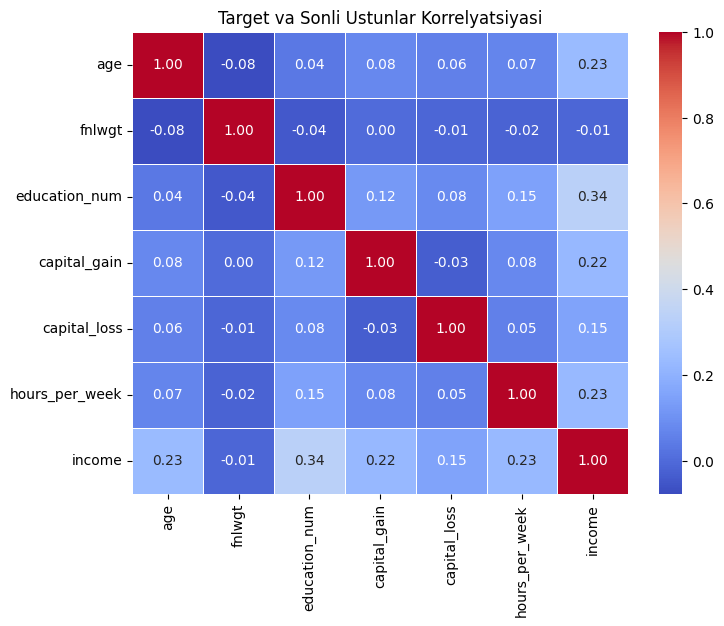

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Faqat sonli ustunlarni ajratib olamiz
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Korrelyatsiyani hisoblaymiz
corr_matrix = df[numeric_cols].corr()

# Qaysi ustun target bilan ko'proq bog'liqligini ko'rish
print(corr_matrix['income'].sort_values(ascending=False))

# Heatmap grafigi
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Target va Sonli Ustunlar Korrelyatsiyasi")
plt.show()

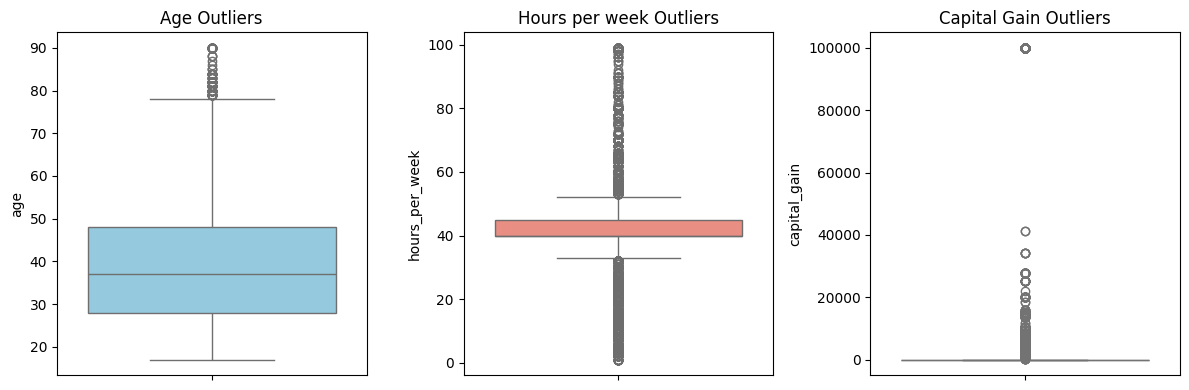

age: 143 ta outlier (0.44%)
hours_per_week: 9008 ta outlier (27.66%)
capital_gain: 2712 ta outlier (8.33%)
capital_loss: 1519 ta outlier (4.67%)


In [9]:
# 1. Boxplot chizib vizual ko'rish
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.boxplot(y=df['age'], color='skyblue')
plt.title("Age Outliers")

plt.subplot(1, 3, 2)
sns.boxplot(y=df['hours_per_week'], color='salmon')
plt.title("Hours per week Outliers")

plt.subplot(1, 3, 3)
sns.boxplot(y=df['capital_gain'], color='lightgreen')
plt.title("Capital Gain Outliers")

plt.tight_layout()
plt.show()

# IQR usuli bilan har bir ustundagi outlierlar sonini aniqlash
features_to_check = ['age', 'hours_per_week', 'capital_gain', 'capital_loss']

for col in features_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    percentage = (outlier_count / len(df)) * 100
    print(f"{col}: {outlier_count} ta outlier ({percentage:.2f}%)")

# capital_gain va capital_loss ustunlarida qatorlarning ~90% dan ortig'i $0$ bo'lgani uchun
# IQR ularni outlier deb ko'rsatadi, lekin bu tabiiy holat (ko'pchilik odamlar sarmoyaviy
# daromad olmaydi, lekin olganlar aniq boyroq bo'ladi).

In [10]:
# Keraksiz ustunlarni o'chiramiz va yangi DataFrame hosil qilamiz
df_new = df.drop(columns=['education', 'fnlwgt']).copy()

# Yangi feature'lar yasash
df_new['capital_net'] = df_new['capital_gain'] - df_new['capital_loss']
df_new['is_married'] = df_new['marital_status'].apply(lambda x: 1 if 'Married' in str(x) else 0)
df_new['work_ratio'] = df_new['hours_per_week'] / df_new['age']

print(df_new[['capital_net', 'is_married', 'work_ratio']].head(10))

   capital_net  is_married  work_ratio
0         2174           0    1.025641
1            0           1    0.260000
2            0           0    1.052632
3            0           1    0.754717
4            0           1    1.428571
5            0           1    1.081081
6            0           1    0.326531
7            0           1    0.865385
8        14084           0    1.612903
9         5178           1    0.952381


In [11]:
# X va y ni ajratib olamiz
X = df_new.drop(columns=['income'])
y = df_new['income']

# Kategorik ustunlar bo'yicha One-Hot Encoding
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

print(f"Jami feature'lar soni: {X_encoded.shape[1]} ta")

Jami feature'lar soni: 84 ta


In [12]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(
    X_encoded, y, test_size=0.15, random_state=42, stratify=y
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=42, stratify=y_temp
)

# Har bir qism hajmini tekshiramiz
print(f"Train to'plami: {X_train.shape[0]}")
print(f"Validation to'plami: {X_valid.shape[0]}")
print(f"Test to'plami: {X_test.shape[0]}")

Train to'plami: 22791
Validation to'plami: 4885
Test to'plami: 4885


In [13]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from xgboost import XGBClassifier

param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0]
}

base_xgb = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='logloss'
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Qidiruvni faqat TRAIN to'plamida bajaramiz
grid_search.fit(X_train, y_train)

# Eng yaxshi parametrlarni chiqaramiz
best_params = grid_search.best_params_
print("\nEng yaxshi parametrlar:")
print(best_params)
print(f"CV dagi eng yuqori ROC-AUC: {grid_search.best_score_:.4f}")

Fitting 3 folds for each of 18 candidates, totalling 54 fits

Eng yaxshi parametrlar:
{'learning_rate': 0.1, 'max_depth': 7, 'subsample': 1.0}
CV dagi eng yuqori ROC-AUC: 0.9273


In [14]:
final_model = XGBClassifier(
    learning_rate=0.1,
    max_depth=7,
    subsample=1.0,
    n_estimators=1000,
    early_stopping_rounds=20,    # 20 ta roundda o'sish bo'lmasa to'xtash
    eval_metric='logloss',
    random_state=42
)

final_model.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],  # Monitoring uchun[cite: 1]
    verbose=10
)

print(f"\nEng yaxshi qadam (best iteration): {final_model.best_iteration}")
print(f"Eng yaxshi validation natijasi: {final_model.best_score:.4f}")

[0]	validation_0-logloss:0.51198
[10]	validation_0-logloss:0.36311
[20]	validation_0-logloss:0.32701
[30]	validation_0-logloss:0.31610
[40]	validation_0-logloss:0.30835
[50]	validation_0-logloss:0.30403
[60]	validation_0-logloss:0.30179
[70]	validation_0-logloss:0.30010
[80]	validation_0-logloss:0.29914
[90]	validation_0-logloss:0.29843
[100]	validation_0-logloss:0.29817
[110]	validation_0-logloss:0.29793
[120]	validation_0-logloss:0.29753
[130]	validation_0-logloss:0.29772
[137]	validation_0-logloss:0.29783

Eng yaxshi qadam (best iteration): 117
Eng yaxshi validation natijasi: 0.2975


In [15]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Test to'plami bo'yicha bashorat qilish
y_pred = final_model.predict(X_test)
y_pred_proba = final_model.predict_proba(X_test)[:, 1]

# 2. Metrikalarni chiqarish
print("=== Xolis Test To'plami Natijalari ===")
print(classification_report(y_test, y_pred))
print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

# 3. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("confusion matrix:")
print(cm)

=== Xolis Test To'plami Natijalari ===
              precision    recall  f1-score   support

           0       0.90      0.95      0.92      3709
           1       0.80      0.66      0.72      1176

    accuracy                           0.88      4885
   macro avg       0.85      0.80      0.82      4885
weighted avg       0.87      0.88      0.87      4885

Test ROC-AUC Score: 0.9328
confusion matrix:
[[3510  199]
 [ 398  778]]


Eng yuqori ahamiyatga ega Top-10 ustun
                          feature  importance_gain
marital_status_Married-civ-spouse         0.578158
                     capital_gain         0.038942
                    education_num         0.037892
                       is_married         0.027241
         occupation_Other-service         0.020091
           relationship_Own-child         0.020044
                     capital_loss         0.017621
       occupation_Exec-managerial         0.013974
     occupation_Handlers-cleaners         0.011611
          occupation_Tech-support         0.009974


<Figure size 1000x600 with 0 Axes>

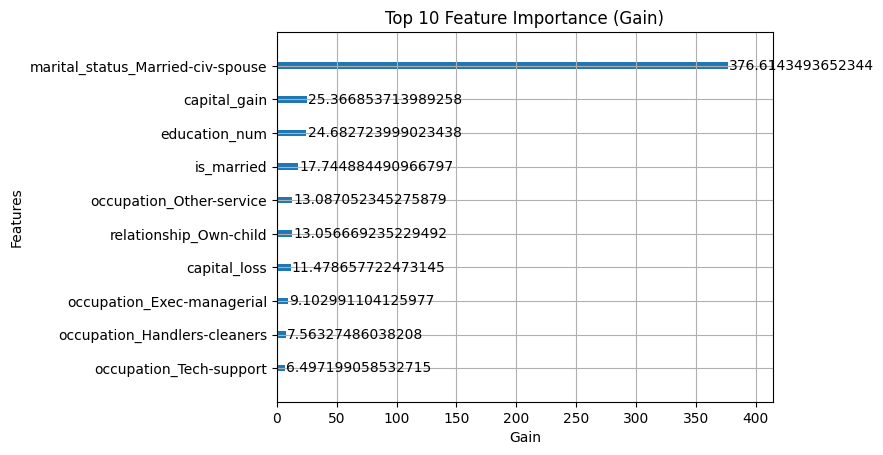

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import plot_importance

importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance_gain': final_model.feature_importances_
}).sort_values(by='importance_gain', ascending=False)

print("Eng yuqori ahamiyatga ega Top-10 ustun")
print(importance_df.head(10).to_string(index=False))

# 2. plot_importance orqali Gain bo'yicha vizualizatsiya
plt.figure(figsize=(10, 6))
plot_importance(final_model, importance_type='gain', max_num_features=10, title="Top 10 Feature Importance (Gain)")
plt.xlabel("Gain")
plt.show()

<Figure size 1000x600 with 0 Axes>

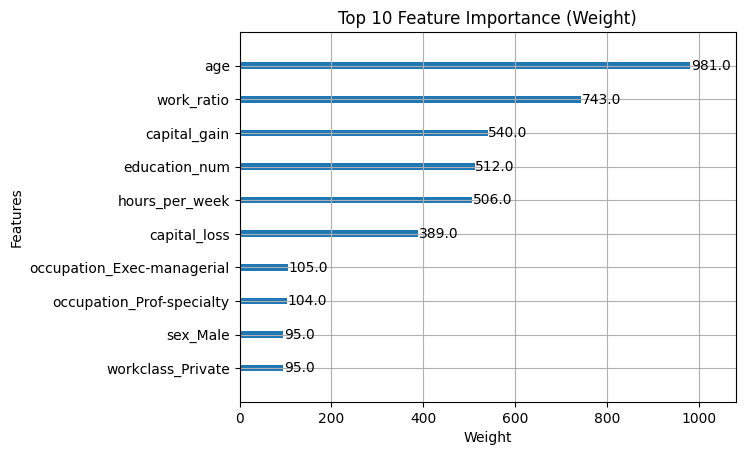

In [18]:
# plot_importance orqali Weight bo'yicha vizualizatsiya
plt.figure(figsize=(10, 6))
plot_importance(final_model, importance_type='weight', max_num_features=10, title="Top 10 Feature Importance (Weight)")
plt.xlabel("Weight")
plt.show()